<a href="https://colab.research.google.com/github/firdhanifah/Program-Kreativitas-Mahasiswa/blob/main/Syntax_Bayesian_Ordinal_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
R.version.string


[1] "R version 4.5.1 (2025-06-13)"

In [ ]:
install.packages(c("brms", "rstan", "bayesplot", "ggplot2"), repos='https://cran.rstudio.com/')

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
library(brms)
library(bayesplot)
library(ggplot2)

In [ ]:
df <- read.csv("data_resiliensi.csv")

# Pastikan variabel Res_Cat dianggap sebagai faktor ordinal
df$Res_Cat <- factor(df$Res_Cat, ordered = TRUE)

In [ ]:
df

asah,asih,asuh,Res_Cat
<int>,<int>,<int>,<ord>
60,56,48,3
57,52,46,2
57,52,46,2
47,49,39,1
52,54,40,2
51,46,41,1
53,48,43,2
60,55,45,3
48,44,33,1


In [ ]:
df

,asah,asih,asuh,Res_Cat
,<int>,<int>,<int>,<ord>
1,60,56,48,3
2,57,52,46,2
3,57,52,46,2
4,47,49,39,1
5,52,54,40,2
6,51,46,41,1


In [ ]:
priors <- c(
  prior(normal(1, 0.8), class = "b", coef = "asah"),
  prior(normal(1, 0.8), class = "b", coef = "asih"),
  prior(normal(1, 0.8), class = "b", coef = "asuh"),
  prior(normal(0, 5), class = "Intercept")
)

In [ ]:
priors <- c(
  prior(normal(1, 0.8), class = "b", coef = "asah"),
  prior(normal(1, 0.8), class = "b", coef = "asih"),
  prior(normal(1, 0.8), class = "b", coef = "asuh"),
  prior(normal(0, 5), class = "Intercept")
)

In [ ]:
priors

prior,class,coef,group,resp,dpar,nlpar,lb,ub,tag,source
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
"normal(1, 0.8)",b,asah,,,,,NA,NA,,user
"normal(1, 0.8)",b,asih,,,,,NA,NA,,user
"normal(1, 0.8)",b,asuh,,,,,NA,NA,,user
"normal(0, 5)",Intercept,,,,,,NA,NA,,user


In [ ]:
model_bayes <- brm(
  formula = Res_Cat ~ asah + asih + asuh,
  data = df,
  family = cumulative("logit"),
  prior = priors,
  chains = 2,     # bisa tambah jadi 4 kalau mau lebih stabil
  iter = 2000,    # jumlah iterasi
  warmup = 1000,  # fase adaptasi
  cores = 2,      # sesuaikan jumlah core CPU di Colab
  seed = 123
)

Compiling Stan program...

Start sampling



In [ ]:
model_bayes <- brm(
  formula = Res_Cat ~ asah + asih + asuh,
  data = df,
  family = cumulative("logit"),
  prior = priors,
  chains = 2,     # bisa tambah jadi 4 kalau mau lebih stabil
  iter = 2000,    # jumlah iterasi
  warmup = 1000,  # fase adaptasi
  cores = 2,      # sesuaikan jumlah core CPU di Colab
  seed = 123
)

Compiling Stan program...

Start sampling



In [ ]:
model_bayes

 Family: cumulative 
  Links: mu = logit 
Formula: Res_Cat ~ asah + asih + asuh 
   Data: df (Number of observations: 19) 
  Draws: 2 chains, each with iter = 2000; warmup = 1000; thin = 1;
         total post-warmup draws = 2000

Regression Coefficients:
             Estimate Est.Error l-95% CI u-95% CI Rhat Bulk_ESS Tail_ESS
Intercept[1]   133.65     35.20    72.91   210.37 1.00      898     1130
Intercept[2]   148.59     38.30    82.56   233.02 1.00      865     1078
asah             1.07      0.45     0.31     2.04 1.00     1062     1010
asih             1.15      0.44     0.36     2.07 1.00      964     1035
asuh             0.55      0.47    -0.26     1.50 1.00     1370     1056

Further Distributional Parameters:
     Estimate Est.Error l-95% CI u-95% CI Rhat Bulk_ESS Tail_ESS
disc     1.00      0.00     1.00     1.00   NA       NA       NA

Draws were sampled using sampling(NUTS). For each parameter, Bulk_ESS
and Tail_ESS are effective sample size measures, and Rhat is the pote

In [ ]:
summary(model_bayes)

 Family: cumulative 
  Links: mu = logit 
Formula: Res_Cat ~ asah + asih + asuh 
   Data: df (Number of observations: 19) 
  Draws: 2 chains, each with iter = 2000; warmup = 1000; thin = 1;
         total post-warmup draws = 2000

Regression Coefficients:
             Estimate Est.Error l-95% CI u-95% CI Rhat Bulk_ESS Tail_ESS
Intercept[1]   133.65     35.20    72.91   210.37 1.00      898     1130
Intercept[2]   148.59     38.30    82.56   233.02 1.00      865     1078
asah             1.07      0.45     0.31     2.04 1.00     1062     1010
asih             1.15      0.44     0.36     2.07 1.00      964     1035
asuh             0.55      0.47    -0.26     1.50 1.00     1370     1056

Further Distributional Parameters:
     Estimate Est.Error l-95% CI u-95% CI Rhat Bulk_ESS Tail_ESS
disc     1.00      0.00     1.00     1.00   NA       NA       NA

Draws were sampled using sampling(NUTS). For each parameter, Bulk_ESS
and Tail_ESS are effective sample size measures, and Rhat is the pote

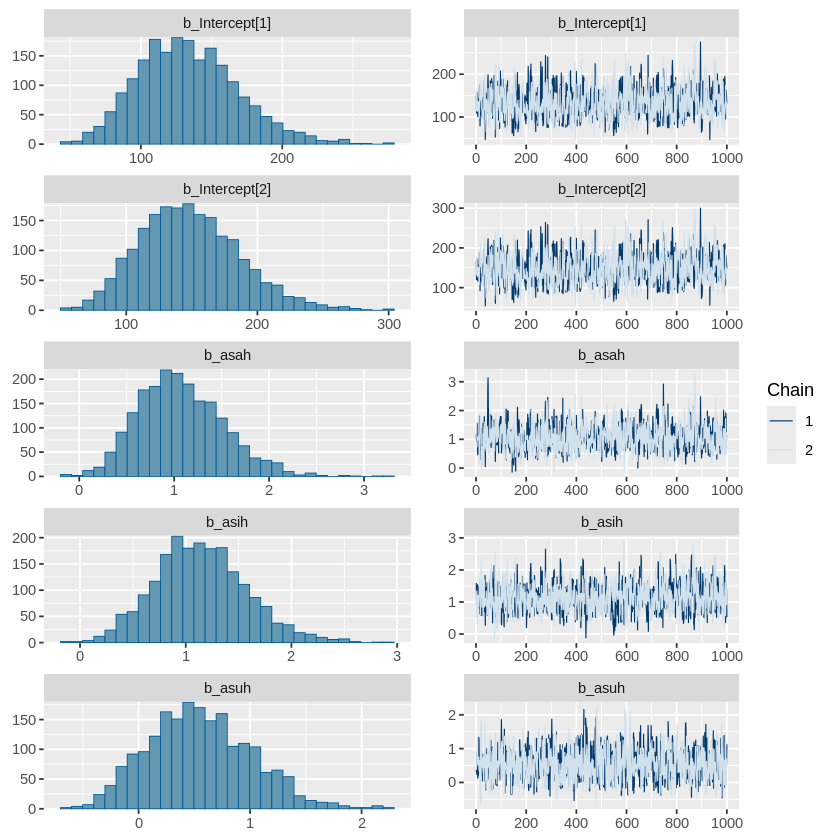

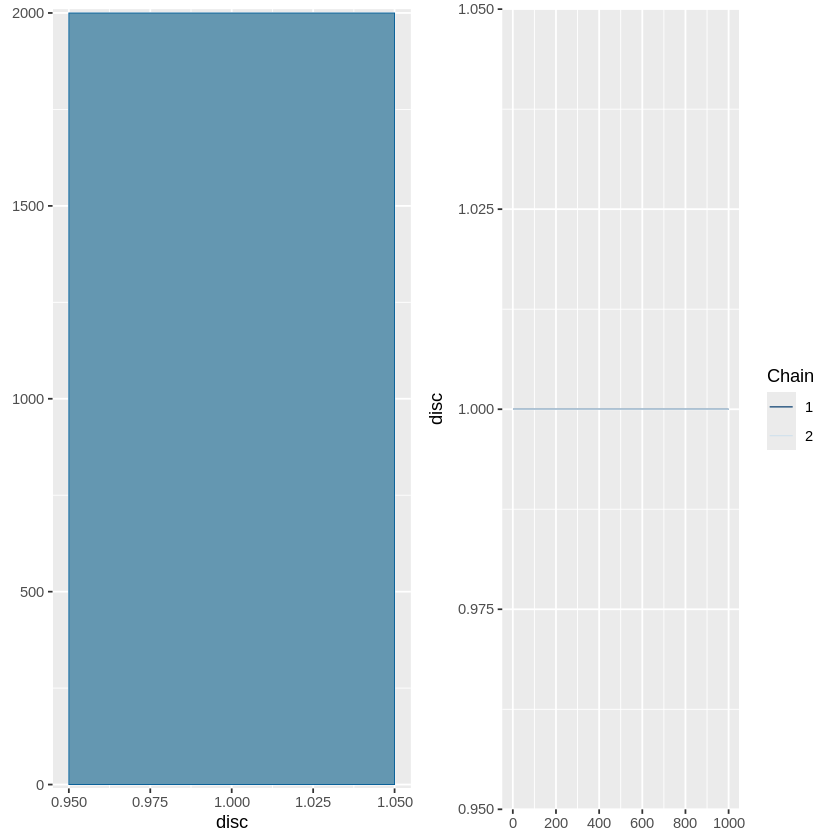

In [ ]:
plot(model_bayes)

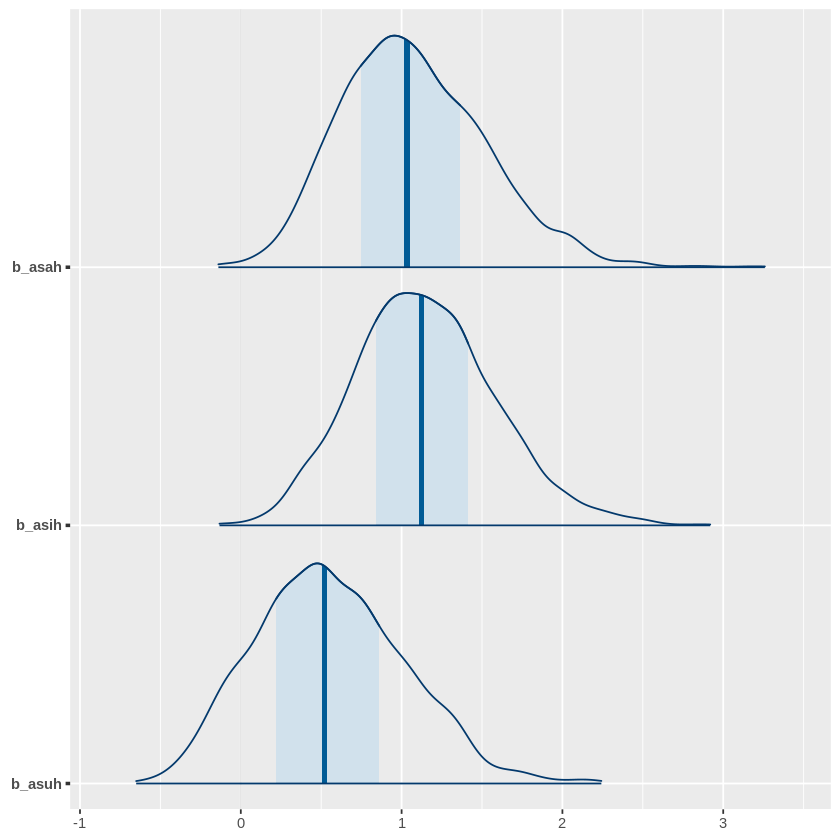

In [ ]:
mcmc_areas(model_bayes, pars = c("b_asah", "b_asih", "b_asuh"))


# gow pimnas gow

In [ ]:
install.packages("openxlsx")
library(openxlsx)
df <- read.xlsx("pimnas.xlsx")

# Pastikan variabel resiliensi dianggap sebagai faktor ordinal
df$resiliensi <- factor(df$resiliensi, ordered = TRUE)
df$stadium <- factor(df$stadium,
                       levels = c(2,3,4),
                       ordered = TRUE)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
# model Bayesian ordinal logistic
model <- brm(
  formula = resiliensi ~ asah + asih + asuh + stadium,
  family = cumulative(link = "logit"),
  data = df, # Changed 'data' to 'df'
  prior = c(
  prior(normal(1, 0.8), class = "b", coef = "asah"),
  prior(normal(1, 0.8), class = "b", coef = "asih"),
  prior(normal(1, 0.8), class = "b", coef = "asuh"),
  prior(normal(0, 5), class = "Intercept")
),
  chains = 4,
  iter = 4000,
  cores = 4
)

Compiling Stan program...

Start sampling



In [ ]:
summary(model)

 Family: cumulative 
  Links: mu = logit 
Formula: resiliensi ~ asah + asih + asuh + stadium 
   Data: df (Number of observations: 20) 
  Draws: 4 chains, each with iter = 4000; warmup = 2000; thin = 1;
         total post-warmup draws = 8000

Regression Coefficients:
             Estimate Est.Error l-95% CI u-95% CI Rhat Bulk_ESS Tail_ESS
Intercept[1]   147.87     38.51    78.42   229.30 1.00     4476     5329
Intercept[2]   164.76     41.08    90.33   250.98 1.00     4263     5094
asah             0.87      0.50    -0.03     1.92 1.00     4902     4407
asih             1.32      0.52     0.40     2.42 1.00     4923     4747
asuh             0.89      0.57    -0.12     2.10 1.00     4548     4698
stadium.L        6.83      4.49    -0.83    16.38 1.00     3401     3804
stadium.Q       -2.60      3.34    -9.26     3.97 1.00     3595     3994

Further Distributional Parameters:
     Estimate Est.Error l-95% CI u-95% CI Rhat Bulk_ESS Tail_ESS
disc     1.00      0.00     1.00     1.00   NA